In [77]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from pathlib import Path
import sys
from scipy import signal as sg

In [78]:
data = np.loadtxt(Path("../Datos reales") / "MCA_Data_01.dat")  #Datos reales  

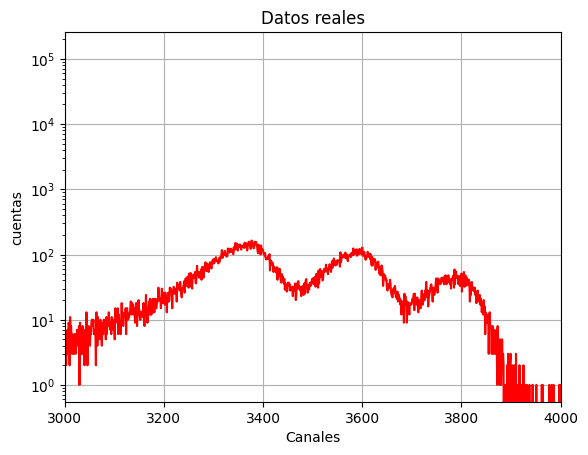

In [79]:
colors = plt.cm.hsv(np.linspace(0, 1, data.shape[1]))
plt.semilogy(data[:,0], color=colors[0], alpha=1)
plt.title("Datos reales")
plt.xlabel("Canales")
plt.ylabel("cuentas")
plt.xlim(3000, 4000)
plt.grid(True)
plt.show()

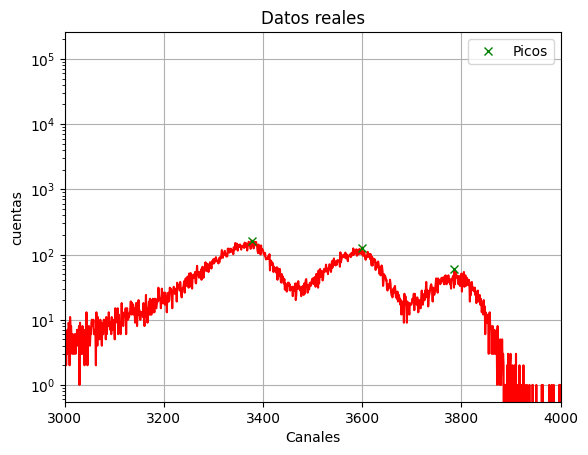

In [80]:
min, max = 3000, 4000

peaks, props = sg.find_peaks(data[min:max, 0], height=10, distance=100, prominence=30)
peaks = peaks + min   # convert back to absolute channel numbers

plt.semilogy(data[:, 0], color=colors[0], alpha=1)
plt.plot(peaks, data[peaks, 0], "x", color="green", label="Picos")
plt.title("Datos reales")
plt.xlabel("Canales")
plt.ylabel("cuentas")
plt.xlim(min, max)
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
x = np.arange(data.shape[0])

fig, ax = plt.subplots()
line, = ax.plot([], [])
ax.set_yscale("log")
ax.set_xlim(min, max)
ax.set_xlabel("Canales")
ax.set_ylabel("cuentas")
ax.grid(True)

def update(i):
    line.set_data(x, data[:, i])
    ax.relim()
    ax.autoscale_view(scalex=False, scaley=True)
    ax.set_title(f"Datos reales — muestra {i + 1}/{data.shape[1]}")
    return (line,)

animation = FuncAnimation(
    fig,
    update,
    frames=data.shape[1],
    interval=100,  # milliseconds per channel
    repeat=True,
    blit=False,
)

display(HTML(animation.to_jshtml()))
plt.close(fig)

In [ ]:
def gaussian(x, mu, sigma=80):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(- (x - mu)**2 / (2 * sigma**2))

def noise(Total_dist, intensidad):
    expected_counts = Total_dist / Total_dist.max() * intensidad
    return np.random.poisson(expected_counts)

def Desplazamiento(DT):
    return np.random.rand() * DT

# Cargamos los datos reales y definimos los canales
data = np.loadtxt(r"..\Datos reales\MCA_Data_01.dat")  #Datos reales  
Canales = np.arange(data.shape[0])
# Definimos los picos de los espectros para cada isótopo
mu_Pu, mu_Am, mu_Cm = 3380, 3600, 3800
#Generamos un arreglo de temperaturas aleatorias y simulamos los datos ruidosos y desplazamiento debido a cada temperatura
Temperaturas = np.random.randint(-200, 201, size=100) 
T = np.random.choice(Temperaturas)
DT = Desplazamiento(T)
espectro = (0.83 * gaussian(Canales, mu_Pu + DT)+ 0.76 * gaussian(Canales, mu_Am + DT)+ 0.68 * gaussian(Canales, mu_Cm + DT))

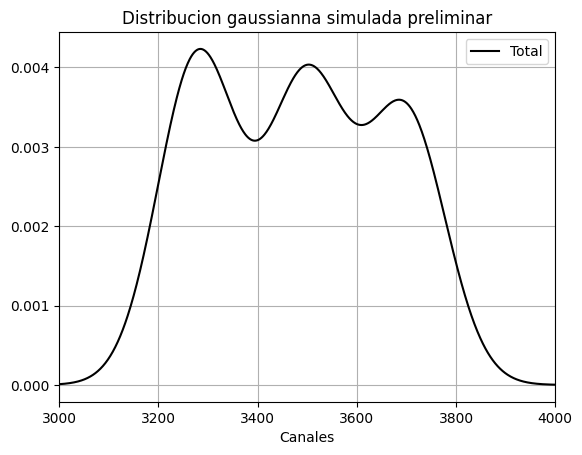

In [ ]:
plt.plot(Canales, espectro, label='Total', color='black')
plt.xlabel("Canales")
plt.title("Distribucion gaussianna simulada preliminar")
plt.legend()
plt.grid(True)
plt.xlim(3000, 4000)
plt.show()

In [ ]:
Temperaturas = np.random.randint(0, 500, size=100) 
Datos = np.zeros((Temperaturas.size, Canales.size))   
Datos_ruidosos = np.zeros((Temperaturas.size, Canales.size))
for i in range(Temperaturas.size):
    DT = Desplazamiento(Temperaturas[i])
    Datos[i] = gaussian(Canales , mu=3380 + DT) * 0.83 + gaussian(Canales , mu=3600 + DT) * 0.76 + gaussian(Canales , mu=3800 + DT) * 0.68
    Datos_ruidosos[i] = noise(Datos[i], 400)



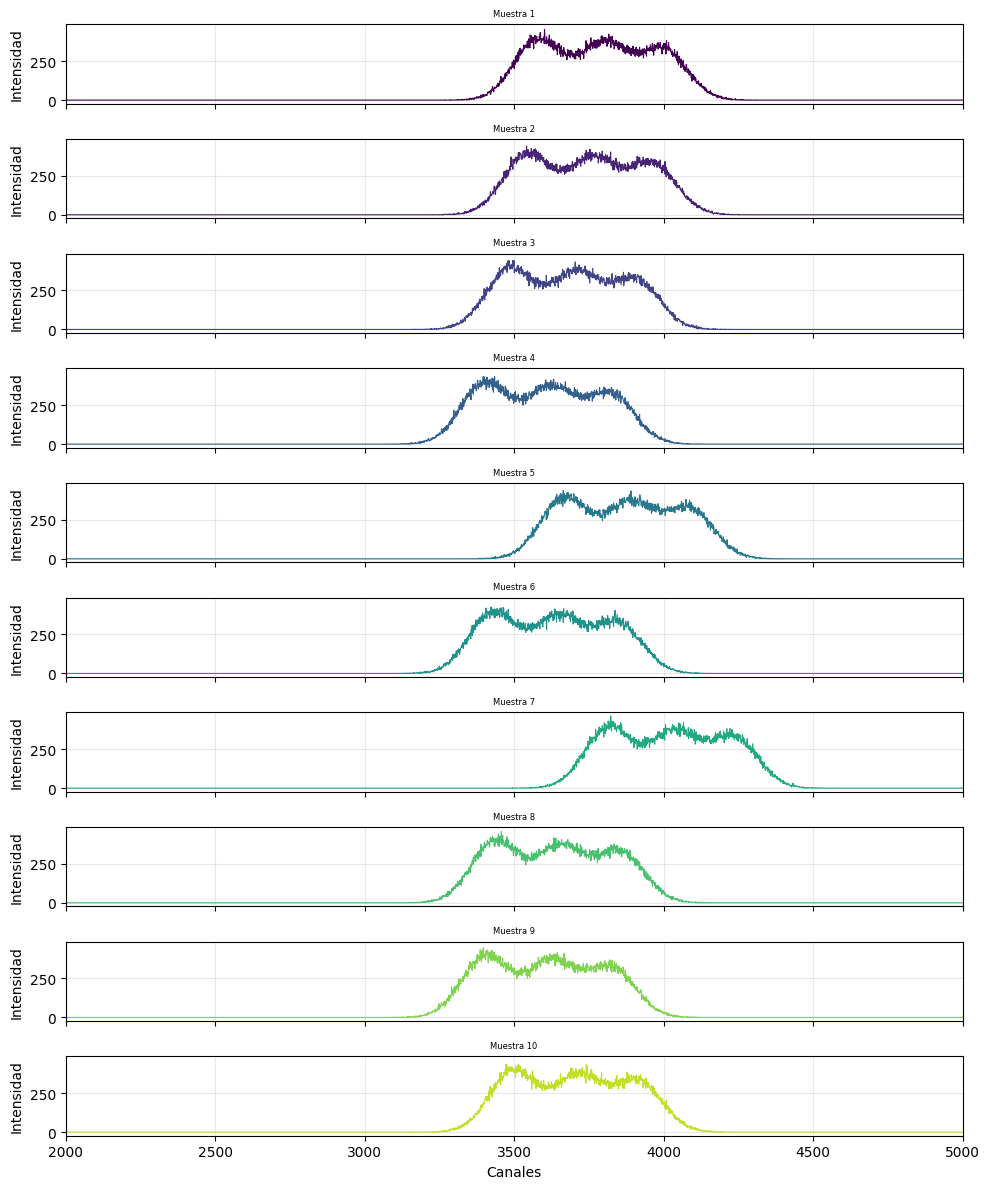

In [ ]:
n = Datos_ruidosos.shape[0]
fig, axes = plt.subplots(10, 1, figsize=(10, 12), sharex=True, sharey=True)
axes = axes.ravel()
colors = plt.cm.viridis(np.linspace(0, 10, n))

for i, ax in enumerate(axes):
    if i < n:
        ax.plot(Canales, Datos_ruidosos[i], color=colors[i], lw=0.8)
        ax.set_title(f"Muestra {i+1}", fontsize=6)
        ax.grid(True, alpha=0.3)
    else:
        ax.axis('off')

for ax in axes[:n]:
    ax.set_ylabel("Intensidad")

axes[-1].set_xlabel("Canales")
plt.xlim(2000, 5000)
plt.tight_layout()
plt.show()

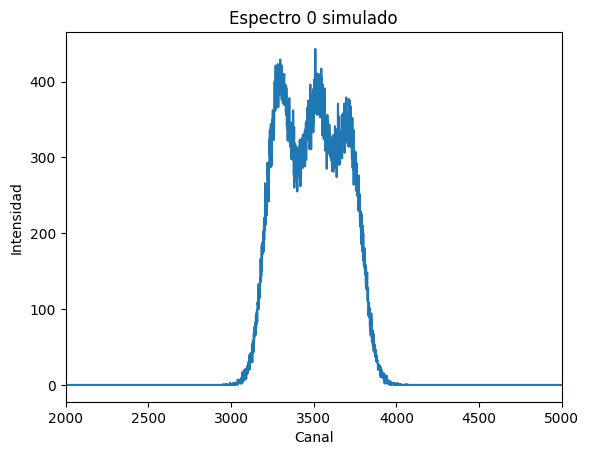

In [ ]:
from pathlib import Path

Datossim = np.loadtxt(Path("..\Datos sinteticos") / "Datos_simulados_0.dat")
plt.plot(Datossim[:, 0], Datossim[:, 1])
plt.xlabel("Canal")
plt.ylabel("Intensidad")
plt.title("Espectro 0 simulado")
plt.xlim(2000, 5000)
plt.show()